# PRCs with near-zero area
Runs where the area under the PRC is ~0, which is where the PRC-weighted mean perturbation time blows up.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PRC_plots import *

In [2]:
# ----------------------------- PARAMETERS -----------------------------
DATA = "PRC_sweep.csv"
AREA_MAX = 1.5e-4       # show runs with |area under PRC| below this
NCOLS = 3
SAVE = False
# ----------------------------------------------------------------------

In [3]:
df = pd.read_csv(DATA)
runs = (df.groupby(["f", "I_h"])[[X, Y, "Hz"]]
        .apply(lambda d: pd.Series({"Hz": d["Hz"].iloc[0], "area": prc_area(d), "mean_t": prc_mean_time(d)}))
        .reset_index())
zero = runs[runs["area"].abs() < AREA_MAX].sort_values("area", key=abs)
zero

,f,I_h,Hz,area,mean_t
51,120,250.0,53.33,-0.000009,7.165256
126,310,200.0,60.20,-0.000018,4.346237
122,300,200.0,59.22,0.000040,-1.546047
149,370,150.0,55.28,0.000106,-0.383783
106,260,200.0,55.40,0.000136,-0.136355


## PRC of each run

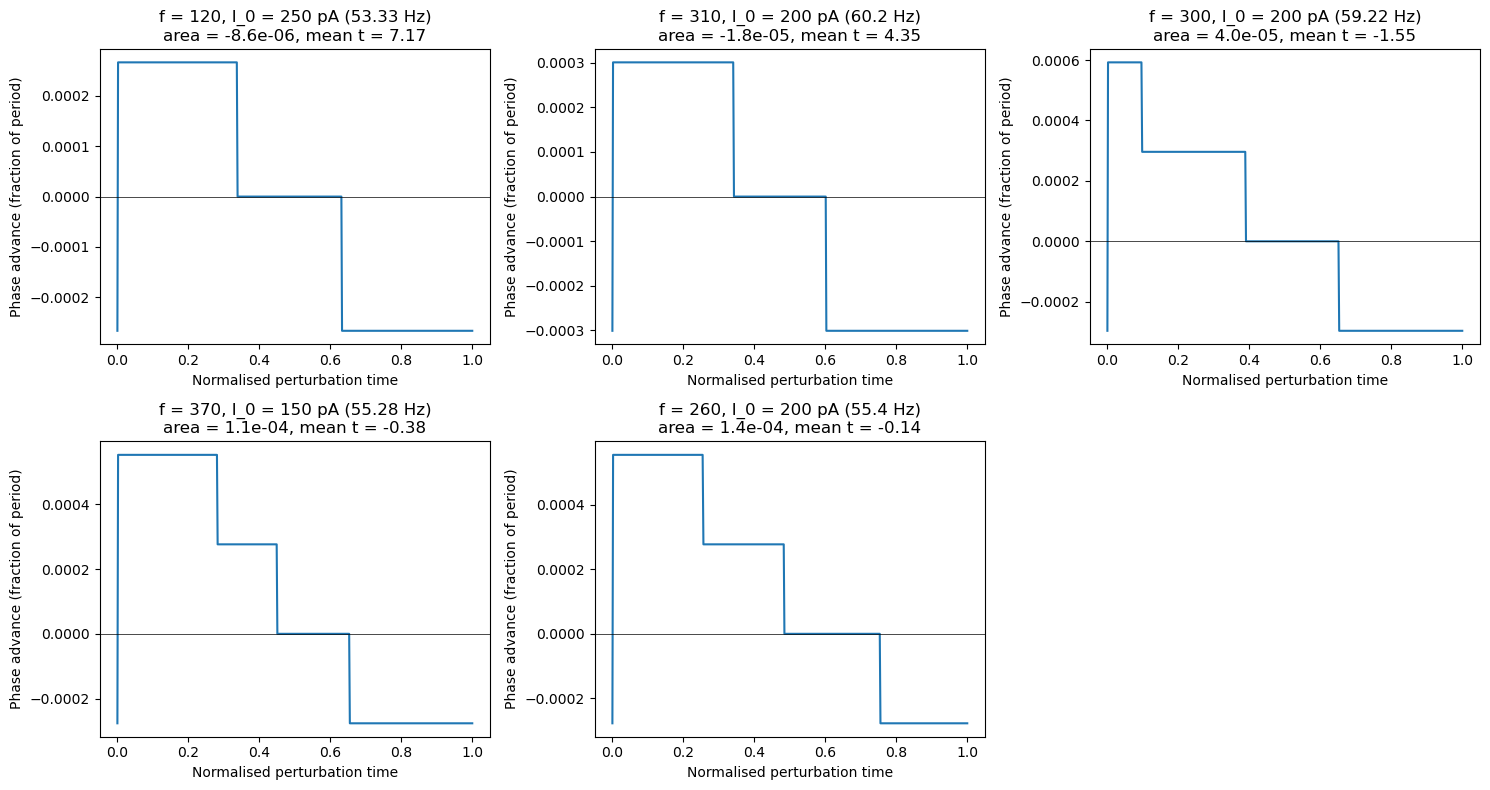

In [4]:
nrows = int(np.ceil(len(zero) / NCOLS))
fig, axes = plt.subplots(nrows, NCOLS, figsize=(5 * NCOLS, 4 * nrows), squeeze=False)
for ax, r in zip(axes.flat, zero.itertuples()):
    d = select(df, f=r.f, I_h=r.I_h).sort_values(X)
    ax.plot(d[X], d[Y])
    ax.axhline(0, color="k", lw=0.5)
    ax.set(xlabel=XLABEL, ylabel=YLABEL,
           title=f"f = {r.f:g}, I_0 = {r.I_h:g} pA ({r.Hz:g} Hz)\narea = {r.area:.1e}, mean t = {r.mean_t:.2f}")
for ax in axes.flat[len(zero):]:
    ax.set_visible(False)
fig.tight_layout()
if SAVE: plt.savefig("PRC_zero_area.png")
plt.show()